# 05 — Error analysis & static robustness
**Phụ trách:** Nguyễn Đức Hưng — H5.1–H5.4.

Notebook chạy cùng CLI, dùng E1 đã merge; không chứa kết quả E2 giả. Official Test không được trích features hoặc dự đoán. Báo cáo là phép đo tái tạo E1 trên phiên bản môi trường hiện tại; manifest ghi hashes/versions.

Chạy từ kernel của `.venv` sau khi cài `pip install -e '.[test]'`. Không truy cập các URL trong dữ liệu.

In [1]:
from pathlib import Path
import os
import sys
import json
import pandas as pd
from IPython.display import display, Markdown, Image

start = Path(os.environ.get("PHISHGUARD_ROOT", Path.cwd())).expanduser().resolve()
PROJECT_ROOT = next(p for p in (start, *start.parents) if (p / "pyproject.toml").is_file() and (p / "src/phishguard_vn").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from phishguard_vn.week5 import run_week5
result = run_week5(PROJECT_ROOT)
TABLES = PROJECT_ROOT / "reports/tables/week5"
FIGURES = PROJECT_ROOT / "reports/figures/week5"
print({k: v for k, v in result.items() if k != "metrics"})
manifest = json.loads((TABLES / "run_manifest.json").read_text())
print("Base revision:", manifest["git_revision"])
print("Fingerprint:", manifest["fingerprint"])
print("Scope:", manifest["evaluation_scope"])
print("Versions:", manifest["versions"])

/Users/nguyenduchung/PhishGuardVN/src/phishguard_vn/data.py:19: DtypeWarning: Columns (6: impersonated_org, 21: status) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


{'selected_model': 'logistic_regression_balanced', 'cached_e1': False, 'cases': 40, 'robustness_cases': 144, 'e2_status': "PREPARED / experimental audit BLOCKED: no E2 manifest supplied. Await Hy's features/dictionary/references and Phúc's predictions/configs/lineage/candidates; Khiêm's bias/pilot evidence is optional for core paired evaluation."}
Base revision: 3e9001cac54f5027637e713c2d5f65d130bb17e3
Fingerprint: a43871519dbd72f2f3daa73522945e7dbc7d55bc6dcf7d013156fca9611f6134
Scope: {'train': 13078, 'validation': 1585, 'test_evaluated': False}
Versions: {'numpy': '2.5.4', 'pandas': '3.1.0', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'tldextract': '5.4.0', 'idna': '3.20', 'joblib': '1.6.0', 'matplotlib': '3.11.2'}


## H5.1 — Held-out evaluation audit

Nối bằng ID; kiểm tra coverage, duplicates, nhãn, fold, domain và ngưỡng. Mỗi OOF row do model mới fit trên hai fold còn lại dự đoán; scaler cũng chỉ fit trên phần đó. Official Validation dùng model fit toàn Train, chỉ báo cáo bổ sung.

AP là average precision. Pooled OOF AP và mean per-fold AP là hai phép tính riêng. Phishing=1, benign=0; FP/1.000 benign có mẫu số là benign support. Cột không xác định ở strata thiếu positive không được thay bằng 0.

,model,evaluation_partition,n_rows,n_benign,n_phishing,accuracy,precision_phishing,recall_phishing,f1_phishing,pr_auc,pr_auc_definition,false_positive_rate,tn,fp,fn,tp,fp_per_1000_benign
0,dummy_most_frequent,group_cv,13078,11004,2074,0.841413,0.000000,0.000000,0.000000,0.158587,average_precision,0.000000,11004,0,2074,0,0.000000
1,dummy_most_frequent,official_validation,1585,1561,24,0.984858,0.000000,0.000000,0.000000,0.015142,average_precision,0.000000,1561,0,24,0,0.000000
2,logistic_regression,group_cv,13078,11004,2074,0.873910,0.728249,0.326905,0.451248,0.592281,average_precision,0.022992,10751,253,1396,678,22.991639
3,logistic_regression,official_validation,1585,1561,24,0.970347,0.255319,0.500000,0.338028,0.293308,average_precision,0.022422,1526,35,12,12,22.421525
4,logistic_regression_balanced,group_cv,13078,11004,2074,0.725876,0.344515,0.807136,0.482908,0.555246,average_precision,0.289440,7819,3185,400,1674,289.440204
5,logistic_regression_balanced,official_validation,1585,1561,24,0.591798,0.034380,0.958333,0.066378,0.274431,average_precision,0.413837,915,646,1,23,413.837284


,model,fold_id,n_rows,n_benign,n_phishing,accuracy,precision_phishing,recall_phishing,f1_phishing,pr_auc,pr_auc_definition,false_positive_rate,tn,fp,fn,tp,fp_per_1000_benign
0,dummy_most_frequent,0.0,4359,3668,691,0.841477,0.000000,0.000000,0.000000,0.158523,average_precision,0.000000,3668,0,691,0,0.000000
1,dummy_most_frequent,1.0,4359,3668,691,0.841477,0.000000,0.000000,0.000000,0.158523,average_precision,0.000000,3668,0,691,0,0.000000
2,dummy_most_frequent,2.0,4360,3668,692,0.841284,0.000000,0.000000,0.000000,0.158716,average_precision,0.000000,3668,0,692,0,0.000000
3,logistic_regression,0.0,4359,3668,691,0.879330,0.744807,0.363242,0.488327,0.612203,average_precision,0.023446,3582,86,440,251,23.446020
4,logistic_regression,1.0,4359,3668,691,0.871989,0.696165,0.341534,0.458252,0.583060,average_precision,0.028081,3565,103,455,236,28.080698
5,logistic_regression,2.0,4360,3668,692,0.870413,0.749020,0.276012,0.403379,0.586832,average_precision,0.017448,3604,64,501,191,17.448201
6,logistic_regression_balanced,0.0,4359,3668,691,0.725855,0.344252,0.806078,0.482460,0.558652,average_precision,0.289258,2607,1061,134,557,289.258451
7,logistic_regression_balanced,1.0,4359,3668,691,0.740766,0.357745,0.798842,0.494181,0.541657,average_precision,0.270174,2677,991,139,552,270.174482
8,logistic_regression_balanced,2.0,4360,3668,692,0.711009,0.332744,0.816474,0.472803,0.572592,average_precision,0.308888,2535,1133,127,565,308.887677


pr_auc           f1_phishing            \
                                  mean       std        mean       std   
model                                                                    
dummy_most_frequent           0.158587  0.000111    0.000000  0.000000   
logistic_regression           0.594032  0.015849    0.449986  0.043073   
logistic_regression_balanced  0.557634  0.015493    0.483148  0.010705   

                             recall_phishing           false_positive_rate  \
                                        mean       std                mean   
model                                                                        
dummy_most_frequent                 0.000000  0.000000            0.000000   
logistic_regression                 0.326929  0.045412            0.022992   
logistic_regression_balanced        0.807131  0.008863            0.289440   

                                        
                                   std  
model                                   
dummy_most_frequent           0.000000  
logistic_regression           0.005331  
logistic_regression_balanced  0.019357

,model,fold_id,tn_delta,fp_delta,fn_delta,tp_delta,precision_phishing_delta,recall_phishing_delta,f1_phishing_delta,pr_auc_delta,false_positive_rate_delta
0,dummy_most_frequent,0,0,0,0,0,0.0,0.0,0.0,0.000000,0.0
1,dummy_most_frequent,1,0,0,0,0,0.0,0.0,0.0,0.000000,0.0
2,dummy_most_frequent,2,0,0,0,0,0.0,0.0,0.0,0.000000,0.0
3,logistic_regression,0,0,0,0,0,0.0,0.0,0.0,-0.000102,0.0
4,logistic_regression,1,0,0,0,0,0.0,0.0,0.0,-0.000203,0.0
5,logistic_regression,2,0,0,0,0,0.0,0.0,0.0,-0.000117,0.0
6,logistic_regression_balanced,0,0,0,0,0,0.0,0.0,0.0,-0.000087,0.0
7,logistic_regression_balanced,1,0,0,0,0,0.0,0.0,0.0,-0.000111,0.0
8,logistic_regression_balanced,2,0,0,0,0,0.0,0.0,0.0,-0.000132,0.0


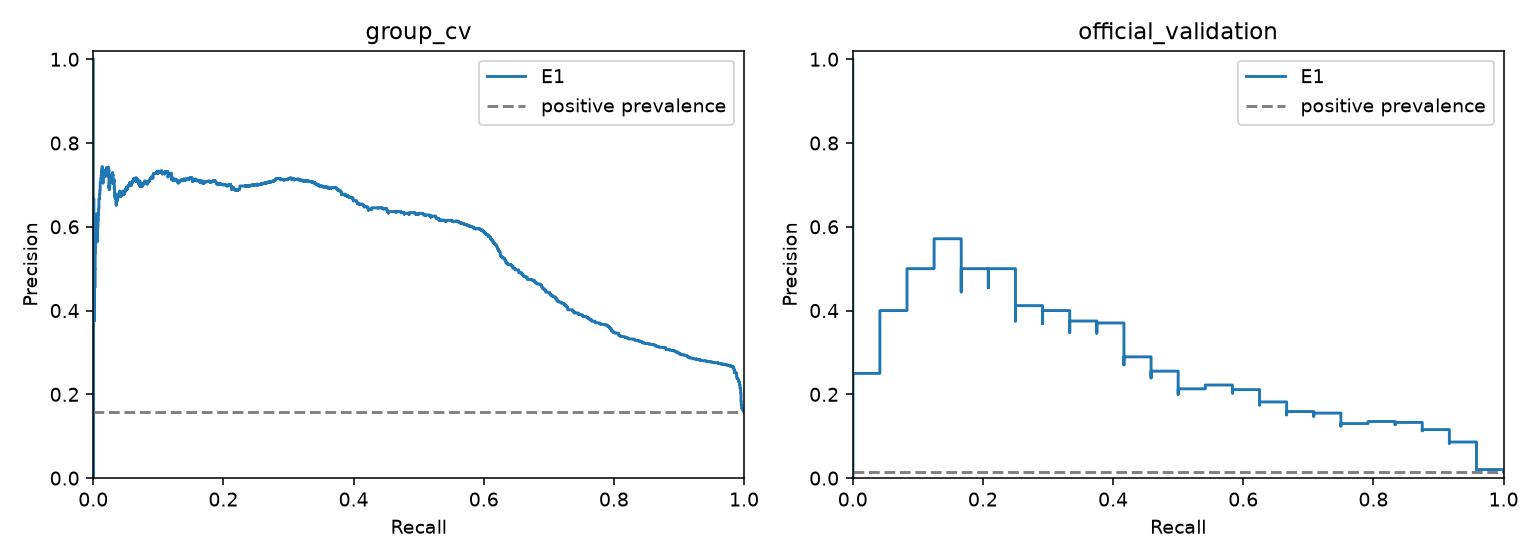

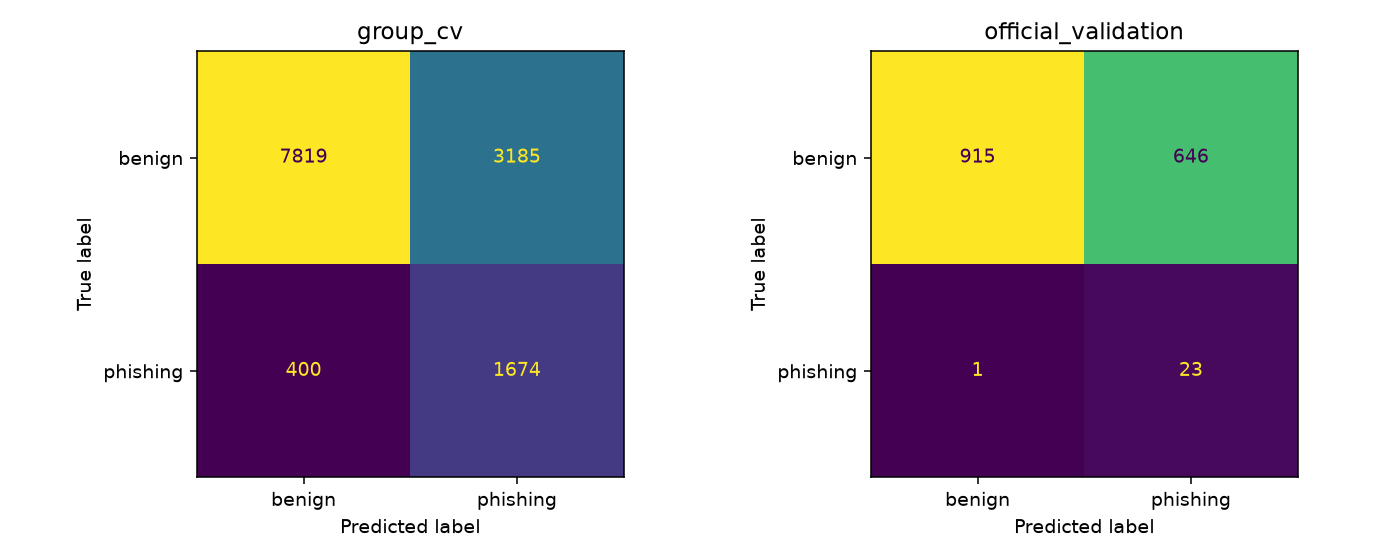

In [2]:
metrics = pd.read_csv(TABLES / "metrics.csv")
fold_metrics = pd.read_csv(TABLES / "fold_metrics.csv")
display(metrics)
display(fold_metrics)
display(fold_metrics.groupby("model")[["pr_auc", "f1_phishing", "recall_phishing", "false_positive_rate"]].agg(["mean", "std"]))
display(pd.read_csv(TABLES / "archived_e1_comparison.csv"))
for name in ["precision_recall.png", "confusion_matrices.png"]:
    display(Image(filename=str(FIGURES / name)))
assert manifest["evaluation_scope"]["test_evaluated"] is False
assert metrics.loc[metrics.evaluation_partition.eq("group_cv"), "n_rows"].eq(13078).all()

## Distribution/source shift

Strata được cố định trước: fold, source, tier, URL length, entropy và domain. Metadata chỉ dùng chẩn đoán, không vào X. Domain/source thường chỉ có một lớp; support nhỏ và confounding giới hạn suy luận. Source shift không tự chứng minh mô hình dùng source shortcut. Validation chỉ có 24 positive nên một mẫu làm recall thay đổi 4,17 điểm phần trăm.

Các giả thuyết trong báo cáo có kiểm chứng đề xuất; không dùng chẩn đoán Validation để chọn model/features/ngưỡng.

,dimension,stratum,train_n,val_n,train_share,val_share,share_delta_val_minus_train
0,source,tinnhiem_org,1659,9,0.126854,0.005678,-0.121176
1,source,tinnhiem_web,3362,271,0.257073,0.170978,-0.086095
2,source,tinnhiemmang,2074,24,0.158587,0.015142,-0.143445
3,source,tranco,4170,935,0.318856,0.589905,0.271049
4,source,tranco_vn,1813,346,0.138630,0.218297,0.079667
5,tier,gold,6638,280,0.507570,0.176656,-0.330914
6,tier,silver,6440,1305,0.492430,0.823344,0.330914
7,label,benign,11004,1561,0.841413,0.984858,0.143445
8,label,phishing,2074,24,0.158587,0.015142,-0.143445


,split,url_len_mean,url_len_median,url_len_min,url_len_max,entropy_mean,entropy_median,entropy_min,entropy_max
0,train,17.114314,15.0,4.0,70.0,3.278779,3.323231,1.459148,4.172405
1,val,13.757729,13.0,5.0,36.0,3.200737,3.238901,1.918296,4.103465


,model,evaluation_partition,dimension,stratum,n_rows,n_benign,n_phishing,accuracy,precision_phishing,recall_phishing,f1_phishing,pr_auc,pr_auc_definition,false_positive_rate,tn,fp,fn,tp,fp_per_1000_benign
32,logistic_regression_balanced,group_cv,source,tinnhiem_org,1659,1659,0,0.935503,0.000000,NaN,NaN,NaN,average_precision,0.064497,1552,107,0,0,64.496685
33,logistic_regression_balanced,group_cv,source,tinnhiem_web,3362,3362,0,0.913444,0.000000,NaN,NaN,NaN,average_precision,0.086556,3071,291,0,0,86.555622
34,logistic_regression_balanced,group_cv,source,tinnhiemmang,2074,0,2074,0.807136,1.000000,0.807136,0.893276,1.000000,average_precision,NaN,0,0,400,1674,NaN
35,logistic_regression_balanced,group_cv,source,tranco,4170,4170,0,0.448681,0.000000,NaN,NaN,NaN,average_precision,0.551319,1871,2299,0,0,551.318945
36,logistic_regression_balanced,group_cv,source,tranco_vn,1813,1813,0,0.730833,0.000000,NaN,NaN,NaN,average_precision,0.269167,1325,488,0,0,269.167126
37,logistic_regression_balanced,official_validation,source,tinnhiem_org,9,9,0,0.888889,0.000000,NaN,NaN,NaN,average_precision,0.111111,8,1,0,0,111.111111
38,logistic_regression_balanced,official_validation,source,tinnhiem_web,271,271,0,0.771218,0.000000,NaN,NaN,NaN,average_precision,0.228782,209,62,0,0,228.782288
39,logistic_regression_balanced,official_validation,source,tinnhiemmang,24,0,24,0.958333,1.000000,0.958333,0.978723,1.000000,average_precision,NaN,0,0,1,23,NaN
40,logistic_regression_balanced,official_validation,source,tranco,935,935,0,0.491979,0.000000,NaN,NaN,NaN,average_precision,0.508021,460,475,0,0,508.021390
41,logistic_regression_balanced,official_validation,source,tranco_vn,346,346,0,0.687861,0.000000,NaN,NaN,NaN,average_precision,0.312139,238,108,0,0,312.138728


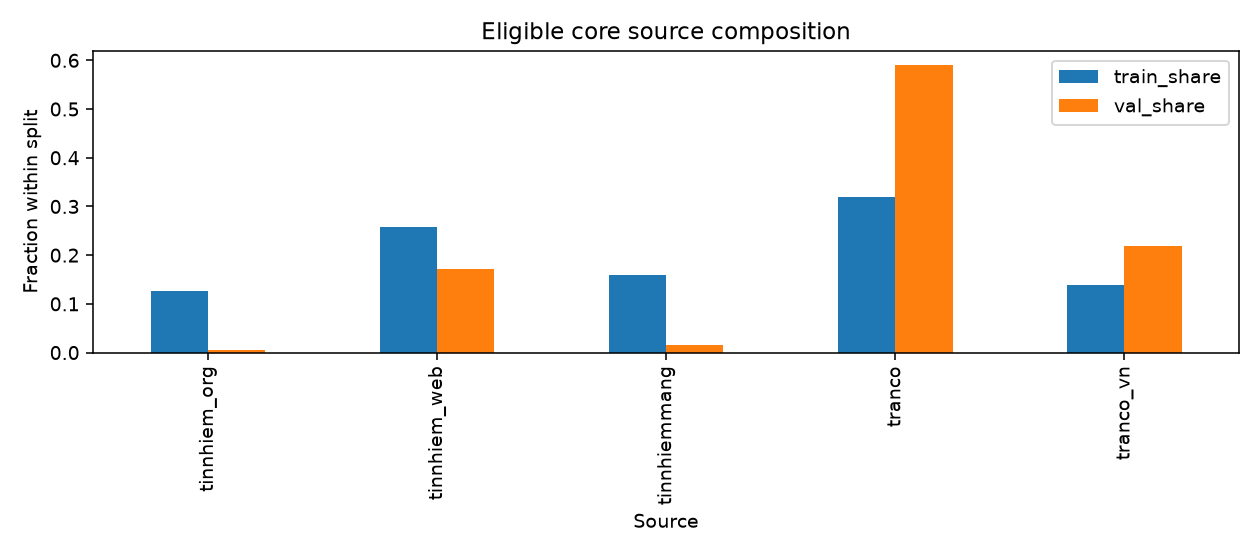

In [3]:
display(pd.read_csv(TABLES / "distribution_shift.csv"))
display(pd.read_csv(TABLES / "numerical_shift.csv"))
strata = pd.read_csv(TABLES / "stratified_metrics.csv")
display(strata.loc[strata.model.eq(result["selected_model"]) & strata.dimension.isin(["source", "url_length_bin", "entropy_bin"])])
display(Image(filename=str(FIGURES / "source_shift.png")))

## H5.2 — Reproducible qualitative review

Chọn 40 FP/FN bằng hash(ID, seed=42), round robin partition/fold/type/source/tier và domain trong từng queue. Không sắp theo score, không cherry-pick. Đây là diversity sample, không phải ước lượng tần suất lỗi trong population.

Mỗi case giữ nhãn gốc và URL text đã vô hiệu hóa, observation, unverified hypothesis, next verification và review status. Nhận xét chỉ mô tả chuỗi/metadata có thể kiểm tra offline. Cần data owner xác minh ngữ nghĩa/nhãn; không truy cập URL nghi ngờ.

In [4]:
cases = pd.read_csv(TABLES / "error_cases.csv", keep_default_na=False)
display(cases)
display(pd.read_csv(TABLES / "error_taxonomy.csv"))
assert len(cases) >= 30 and cases.id.is_unique
assert cases.review_status.str.contains("human_verification_pending").all()
assert not cases.url_safe.str.contains("://", regex=False).any()
display(cases.groupby(["evaluation_partition", "fold_id", "outcome"], dropna=False).size().rename("cases").reset_index())

,id,model,evaluation_partition,fold_id,source,tier,true_label,predicted_label,score,outcome,sampling_seed,sampling_hash,taxonomy,url_safe,observation,hypothesis,next_verification,review_status,label_review_status,source_effects_status
0,6e2fe1fa-4187-535a-9e4d-ed4f04f521d8,logistic_regression_balanced,group_cv,0.0,tinnhiemmang,gold,1,0,0.488118,FN,42,039a3d43b2100e264cf47bba42928eaa3c7229ed10319e...,unknown,URL_TEXT: bhdtw[.]cn,No cue in the predefined static checklist; Dat...,Lexical representation and source composition ...,Inspect fold-local feature contributions and a...,static_observation_complete;human_verification...,unverified_original_label_retained,population_hypothesis_not_case_causality
1,68b21c18-0edb-5b77-ac39-6054afcfbe75,logistic_regression_balanced,group_cv,0.0,tinnhiemmang,silver,1,0,0.461597,FN,42,09b3a062164a29c19f84f9b675e13c2db6f06ab980e6ff...,unknown,URL_TEXT: baohomnay[.]com,No cue in the predefined static checklist; Dat...,Lexical representation and source composition ...,Inspect fold-local feature contributions and a...,static_observation_complete;human_verification...,unverified_original_label_retained,population_hypothesis_not_case_causality
2,2aee13a2-eafb-5171-819f-e246b1c867a3,logistic_regression_balanced,group_cv,0.0,tinnhiem_org,gold,0,1,0.841241,FP,42,05ba6a9098226c598bb7a950ce297fe01d387fc3ef4f3d...,domain_subdomain,URL_TEXT: https[:]//www[.]vntrip[.]vn,Subdomain labels=1; Dataset label=benign; obse...,Lexical representation and source composition ...,Inspect fold-local feature contributions and a...,static_observation_complete;human_verification...,unverified_original_label_retained,population_hypothesis_not_case_causality
3,9d403305-972e-51b5-af2d-8dc977647666,logistic_regression_balanced,group_cv,0.0,tinnhiem_web,gold,0,1,0.507290,FP,42,00cd0771834709469126437e985f5c7707371cd85ed185...,unknown,URL_TEXT: hancapquang[.]net,No cue in the predefined static checklist; Dat...,Lexical representation and source composition ...,Inspect fold-local feature contributions and a...,static_observation_complete;human_verification...,unverified_original_label_retained,population_hypothesis_not_case_causality
4,7a73788a-0f81-5e4a-8573-e07c85e2fb19,logistic_regression_balanced,group_cv,0.0,tranco,silver,0,1,0.704269,FP,42,000a73550c381f15c13495806115d5d25ddbb4b1beab28...,lexical_patterns,URL_TEXT: abo2sadam[.]net,Contains digit/hyphen/underscore or login/veri...,Lexical representation and source composition ...,Inspect fold-local feature contributions and a...,static_observation_complete;human_verification...,unverified_original_label_retained,population_hypothesis_not_case_causality
5,4e8262a1-336e-5819-9e98-d06e12be0475,logistic_regression_balanced,group_cv,0.0,tranco_vn,silver,0,1,0.606205,FP,42,018989aa541c505f6189bff2913b0032038d39d7521c83...,unknown,URL_TEXT: bizflycloud[.]vn,No cue in the predefined static checklist; Dat...,Lexical representation and source composition ...,Inspect fold-local feature contributions and a...,static_observation_complete;human_verification...,unverified_original_label_retained,population_hypothesis_not_case_causality
6,82998996-e80e-5061-8609-18d984e0c795,logistic_regression_balanced,group_cv,1.0,tinnhiemmang,gold,1,0,0.426888,FN,42,01f4d257f6bf740f01d37093d449bf531656f8de089485...,unknown,URL_TEXT: tuantaynguyen[.]net,No cue in the predefined static checklist; Dat...,Lexical representation and source composition ...,Inspect fold-local feature contributions and a...,static_observation_complete;human_verification...,unverified_original_label_retained,population_hypothesis_not_case_causality
7,679a800b-9657-5e0b-ac73-5aab35bf14d2,logistic_regression_balanced,group_cv,1.0,tinnhiemmang,silver,1,0,0.486029,FN,42,032f34ffb923b578c08cf3fdba6fe71418c7b902be6c15...,unknown,URL_TEXT: dieniex[.]com,No cue in the predefined static checklist; Dat...,Lexical representation and source composition ...,Inspect fold-local feature contributions and a...,static_observation_complete;human_veri

,category,definition,sample_cases,interpretation
0,brand_cues,Visible generic brand-like tokens; no proof of...,2,"multi-label sample cue count, not population f..."
1,domain_subdomain,Multiple subdomain labels,6,"multi-label sample cue count, not population f..."
2,lexical_patterns,"Digits, hyphens, or action tokens in the string",5,"multi-label sample cue count, not population f..."
3,url_complexity,"Long URL, path or query",0,"multi-label sample cue count, not population f..."
4,idna_ip,"Unicode, punycode or IP literal",0,"multi-label sample cue count, not population f..."
5,source_effects,Source-label confounding is a population hypot...,0,"multi-label sample cue count, not population f..."
6,label_uncertainty,Dataset label retained; semantic confirmation ...,0,"multi-label sample cue count, not population f..."
7,unknown,No selected static cue; mechanism undetermined,30,"multi-label sample cue count, not population f..."


,evaluation_partition,fold_id,outcome,cases
0,group_cv,0.0,FN,4
1,group_cv,0.0,FP,8
2,group_cv,1.0,FN,4
3,group_cv,1.0,FP,8
4,group_cv,2.0,FN,4
5,group_cv,2.0,FP,7
6,official_validation,,FN,1
7,official_validation,,FP,4


## H5.3 — Static URL robustness (độc lập E2)

6 reserved-example bases × 24 deterministic transformations: subdomain/path/query/long URL/encoding/Unicode-IDNA/punycode/homoglyph/brand/shortener-like/IP/malformed. Không có request mạng. Host case/default port được kiểm tra cùng HTTP resource; các thay đổi khác là label-unknown.

Parser validity phản ánh contract hiện tại, không xác nhận mọi browser/RFC. URL lỗi có missing features là rejection dự kiến. Paired score/flip chỉ dùng các cặp dự đoán hợp lệ; không có ground truth cho URL biến đổi nên không tính accuracy/F1. Flip không mặc định là model error.

,transformation,label_policy,n_cases,parser_valid_rate,expected_validity_pass_rate,finite_feature_coverage,paired_predictions,prediction_flip_rate,stability,mean_score_shift,mean_abs_score_shift,max_abs_score_shift,predictor_errors
0,host_case,label-preserving,6,1.0,1.0,1.0,6,0.000000,1.000000,0.016706,0.016706,0.039328,0
1,default_port,label-preserving,6,1.0,1.0,1.0,6,0.000000,1.000000,0.109449,0.109449,0.243438,0
2,subdomain,label-unknown,6,1.0,1.0,1.0,6,0.166667,0.833333,0.215454,0.215454,0.480128,0
3,deep_subdomain,label-unknown,6,1.0,1.0,1.0,6,0.166667,0.833333,0.302337,0.302337,0.977368,0
4,path_query,label-unknown,6,1.0,1.0,1.0,6,0.000000,1.000000,0.200217,0.200217,0.397155,0
5,long_path,label-unknown,6,1.0,1.0,1.0,6,0.166667,0.833333,0.302337,0.302337,0.977368,0
6,long_query,label-unknown,6,1.0,1.0,1.0,6,0.166667,0.833333,0.302337,0.302337,0.977368,0
7,percent_encoding,label-unknown,6,1.0,1.0,1.0,6,0.166667,0.833333,0.297797,0.297797,0.971831,0
8,double_encoding,label-unknown,6,1.0,1.0,1.0,6,0.166667,0.833333,0.291914,0.291914,0.964156,0
9,unicode_idna,label-unknown,6,1.0,1.0,1.0,6,0.000000,1.000000,0.122569,0.129479,0.264962,0


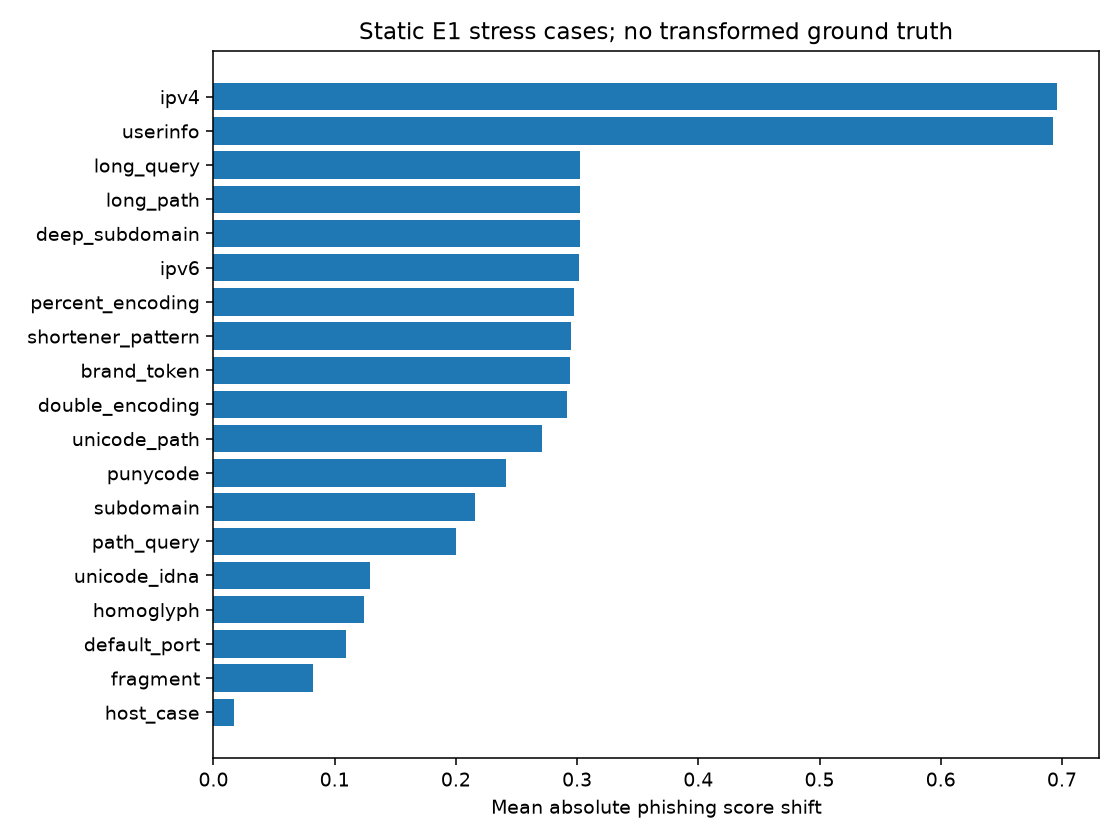

# Week 5 — Static URL robustness

Predictor: logistic_regression_balanced.

Six static reserved-example URLs × 24 deterministic transformations; no network requests. No ground-truth labels are assigned to stress strings.

Host case and scheme-default ports preserve the HTTP resource under the stated specification. All other transformations are label-unknown, including fragments (client-side routing may change semantics).
Validity is the existing parser/extractor contract, not browser acceptance or an RFC compliance claim. IPv4/IPv6 are feature-valid although domain-group training excluded IPs.

| transformation | label_policy | n_cases | parser_valid_rate | expected_validity_pass_rate | finite_feature_coverage | paired_predictions | prediction_flip_rate | stability | mean_score_shift | mean_abs_score_shift | max_abs_score_shift | predictor_errors |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| host_case | label-preserving | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.0000 | 1.0000 | 0.0167 | 0.0167 | 0.0393 | 0 |
| default_port | label-preserving | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.0000 | 1.0000 | 0.1094 | 0.1094 | 0.2434 | 0 |
| subdomain | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.2155 | 0.2155 | 0.4801 | 0 |
| deep_subdomain | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.3023 | 0.3023 | 0.9774 | 0 |
| path_query | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.0000 | 1.0000 | 0.2002 | 0.2002 | 0.3972 | 0 |
| long_path | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.3023 | 0.3023 | 0.9774 | 0 |
| long_query | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.3023 | 0.3023 | 0.9774 | 0 |
| percent_encoding | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.2978 | 0.2978 | 0.9718 | 0 |
| double_encoding | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.2919 | 0.2919 | 0.9642 | 0 |
| unicode_idna | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.0000 | 1.0000 | 0.1226 | 0.1295 | 0.2650 | 0 |
| punycode | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.2414 | 0.2414 | 0.6316 | 0 |
| homoglyph | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.0000 | 1.0000 | 0.1181 | 0.1245 | 0.2544 | 0 |
| brand_token | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.2942 | 0.2942 | 0.9703 | 0 |
| shortener_pattern | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.2953 | 0.2953 | 0.9711 | 0 |
| ipv4 | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.8333 | 0.1667 | -0.6958 | 0.6958 | 0.9450 | 0 |
| ipv6 | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.3019 | 0.3019 | 0.9750 | 0 |
| userinfo | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.8333 | 0.1667 | -0.6925 | 0.6925 | 0.9312 | 0 |
| fragment | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.0000 | 1.0000 | -0.0823 | 0.0823 | 0.1526 | 0 |
| unicode_path | label-unknown | 6 | 1.0000 | 1.0000 | 1.0000 | 6 | 0.1667 | 0.8333 | 0.2712 | 0.2712 | 0.9381 | 0 |
| bad_port | label-unknown | 6 | 0.0000 | 1.0000 | 0.0000 | 0 | undefined | undefined | undefined | undefined | undefined | 0 |
| bad_ipv6 | label-unknown | 6 | 0.0000 | 1.0000 | 0.0000 | 0 | undefined | undefined | undefined | undefined | undefined | 0 |
| missing_host | label-unknown | 6 | 0.0000 | 1.0000 | 0.0000 | 0 | undefined | undefined | undefined | undefined | undefined | 0 |
| host_whitespace | label-unknown | 6 | 0.0000 | 1.0000 | 0.0000 | 0 | undefined | undefined | undefined | undefined | undefined | 0 |
| unresolved_suffix | label-unknown | 6 | 0.0000 | 1.0000 | 0.0000 | 0 | undefined | undefined | undefined | undefined | undefined | 0 |

Largest observed flip rates (small unlabeled suite; not error rates):

| transformation | paired_predictions | prediction_flip_rate | mean_abs_score_shift |
|---|---|---|---|
| ipv4 | 6 | 0.8333 | 0.6958 |
| userinfo | 6 | 0.8333 | 0.6925 |
| unicode_path | 6 | 0.1667 | 0.2712 |

Finite-feature coverage uses all transformed cases as denominator; malformed cases correctly yield missing features. Expected-validity pass rate distinguishes intended rejection from failures. Paired-prediction denominators are explicit; undefined flip/shift means no valid prediction pair.

Flip rate is threshold stability, not classification error. Scores are uncalibrated and no accuracy/F1 is computed. Six synthetic bases are a small stress suite, not an estimate of real-world robustness. Some malformed transformations generate the same string for multiple bases, so 144 rows are not 144 independent inputs. Long paths and IPs probe inputs uncommon or absent in E1 training. Encoding may change server routing; no label preservation is asserted for it.

Full specifications, safe strings, parser reasons and paired scores: tables/week5/robustness_cases.csv. Reuse run_robustness(predictor) with any local E2 score adapter; do not perform network lookups.


In [5]:
robustness = pd.read_csv(TABLES / "robustness_summary.csv")
display(robustness)
assert robustness.n_cases.sum() == 144
assert robustness.expected_validity_pass_rate.eq(1).all()
assert robustness.predictor_errors.sum() == 0
display(Image(filename=str(FIGURES / "robustness_shift.png")))
display(Markdown((PROJECT_ROOT / "reports/week5_robustness.md").read_text()))

## H5.4 — E2 audit & KD readiness

E2 chỉ chạy khi cung cấp manifest có hash, feature dictionary/order/version, references, predictions, configs và training lineage. Loaders kiểm tra matched IDs/folds, metadata leakage, finite values, lexical contract và fold-local/external reference scope. Producer declarations vẫn cần review code và provenance. Có adapter callable local để chạy lại robustness; không tự train Teacher.

Protocol KD chuẩn bị outer/inner domain folds, cross-fitted soft targets, Train-only tuning, hard-only vs KD, AP/F1/Recall–FPR/size/latency/uncertainty và negative results. Synthetic fixtures chỉ kiểm tra logic.

Giới hạn: chỉ ba folds; Validation ít positives; source-label confounding; nhóm URL tĩnh nhỏ; semantic label review còn pending. Xem handoff để nhận artifacts từ Hy/Phúc/Khiêm và continuation prompt.

In [6]:
print(manifest["e2_status"])
e2_comparison = TABLES / "e2_comparison.csv"
if "BLOCKED" not in manifest["e2_status"] and e2_comparison.is_file():
    display(pd.read_csv(e2_comparison))
# Report paths stay relative to repository when rendered outside the notebook.
report_text = (PROJECT_ROOT / "reports/week5_evaluation.md").read_text()
report_text = report_text.replace("](figures/week5/", "](../reports/figures/week5/").replace("](week5_robustness.md)", "](../reports/week5_robustness.md)")
display(Markdown(report_text))
print("Handoff:", PROJECT_ROOT / "docs/week5_hung_handoff.md")
print("KD protocol:", PROJECT_ROOT / "docs/kd_evaluation_protocol.md")

PREPARED / experimental audit BLOCKED: no E2 manifest supplied. Await Hy's features/dictionary/references and Phúc's predictions/configs/lineage/candidates; Khiêm's bias/pilot evidence is optional for core paired evaluation.


# PhishGuardVN — Week 5 evaluation (Hưng)

## Status and provenance

H5.1 DONE; H5.2 DONE for reproducible static review (human semantic checks pending); H5.3 DONE. H5.4 PREPARED for E2 and KD; actual E2 audit BLOCKED until producer artifacts arrive.

GitHub PRs #1–#4 verified merged on 2026-10-31. Local checkout initially d5555da; fetched and switched to detached merged main 3e9001c, preserving the original branch. No commits, pushes or merges performed. No Week-5 plan found in the checkout; scope follows the supplied H5.1–H5.4 request.

Runtime base revision: `3e9001cac54f5027637e713c2d5f65d130bb17e3`. Exact input/source hashes, versions, cache fingerprint and prediction/model hashes: tables/week5/run_manifest.json. This is a fresh reconstruction via merged `run_baseline`, not a claim that an unavailable Week-4 model was recovered. Original archived Week-4 tables were not overwritten.

12 lexical features; 13,078 eligible core train IDs; 3 unchanged domain folds; seed=42; scaler fit separately on each fitting fold; threshold=0.5. Two unresolved train/phishing URLs remain in the raw dataset, excluded with reasons. No official test features or predictions generated. Metadata (including source/tier) stays outside X.

Selected E1: **logistic_regression_balanced** by existing mean-CV-F1 rule, AP tie-break. Reconstructed predictions cover every eligible ID once per model/partition and pass label/fold/group/threshold checks. All available local Week-4 feature/domain/fold handoffs match by ID.

## H5.1 — measured evaluation

PR-AUC below means average precision (AP). Pooled OOF AP is a separate calculation from mean per-fold AP; AP depends on prevalence. P/R/F1 refer to phishing=1. Undefined recall/F1/AP in zero-positive strata remain missing.

| model | evaluation_partition | n_rows | n_phishing | tn | fp | fn | tp | precision_phishing | recall_phishing | f1_phishing | pr_auc | false_positive_rate | fp_per_1000_benign |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| dummy_most_frequent | group_cv | 13078 | 2074 | 11004 | 0 | 2074 | 0 | 0.0000 | 0.0000 | 0.0000 | 0.1586 | 0.0000 | 0.0000 |
| dummy_most_frequent | official_validation | 1585 | 24 | 1561 | 0 | 24 | 0 | 0.0000 | 0.0000 | 0.0000 | 0.0151 | 0.0000 | 0.0000 |
| logistic_regression | group_cv | 13078 | 2074 | 10751 | 253 | 1396 | 678 | 0.7282 | 0.3269 | 0.4512 | 0.5923 | 0.0230 | 22.9916 |
| logistic_regression | official_validation | 1585 | 24 | 1526 | 35 | 12 | 12 | 0.2553 | 0.5000 | 0.3380 | 0.2933 | 0.0224 | 22.4215 |
| logistic_regression_balanced | group_cv | 13078 | 2074 | 7819 | 3185 | 400 | 1674 | 0.3445 | 0.8071 | 0.4829 | 0.5552 | 0.2894 | 289.4402 |
| logistic_regression_balanced | official_validation | 1585 | 24 | 915 | 646 | 1 | 23 | 0.0344 | 0.9583 | 0.0664 | 0.2744 | 0.4138 | 413.8373 |

Mean and sample standard deviation across three folds (descriptive; not a confidence interval):

| model | pr_auc_mean | pr_auc_std | f1_phishing_mean | f1_phishing_std | recall_phishing_mean | recall_phishing_std | false_positive_rate_mean | false_positive_rate_std |
|---|---|---|---|---|---|---|---|---|
| dummy_most_frequent | 0.1586 | 0.0001 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| logistic_regression | 0.5940 | 0.0158 | 0.4500 | 0.0431 | 0.3269 | 0.0454 | 0.0230 | 0.0053 |
| logistic_regression_balanced | 0.5576 | 0.0155 | 0.4831 | 0.0107 | 0.8071 | 0.0089 | 0.2894 | 0.0194 |

Archived Week-4 comparison: identical confusion counts=True; maximum absolute per-fold AP difference=0.000202656. Current runtime versions differ from the archived environment; the AP difference is recorded, not silently replaced by old metrics or attributed to a verified cause. See archived_e1_comparison.csv.

![PR curves](../reports/figures/week5/precision_recall.png)

![Confusion matrices](../reports/figures/week5/confusion_matrices.png)

Observation: selected E1 pooled OOF FPR=28.94% (289.4 FP/1,000 benign), recall=80.71%; validation FPR=41.38%, recall=95.83%. Validation has only 24 positives; one case changes recall by 4.17 percentage points.

Strata tables include every fold, source, tier, fixed URL-length/entropy bin and domain, with supports/confusion counts. Domain strata are sparse and often single-class: no ranking as causal error mechanisms. They are diagnostics, never features or a validation tuning signal.

### Distribution/source shift

| dimension | stratum | train_n | val_n | train_share | val_share | share_delta_val_minus_train |
|---|---|---|---|---|---|---|
| source | tinnhiem_org | 1659 | 9 | 0.1269 | 0.0057 | -0.1212 |
| source | tinnhiem_web | 3362 | 271 | 0.2571 | 0.1710 | -0.0861 |
| source | tinnhiemmang | 2074 | 24 | 0.1586 | 0.0151 | -0.1434 |
| source | tranco | 4170 | 935 | 0.3189 | 0.5899 | 0.2710 |
| source | tranco_vn | 1813 | 346 | 0.1386 | 0.2183 | 0.0797 |
| tier | gold | 6638 | 280 | 0.5076 | 0.1767 | -0.3309 |
| tier | silver | 6440 | 1305 | 0.4924 | 0.8233 | 0.3309 |
| label | benign | 11004 | 1561 | 0.8414 | 0.9849 | 0.1434 |
| label | phishing | 2074 | 24 | 0.1586 | 0.0151 | -0.1434 |

| split | url_len_mean | url_len_median | url_len_min | url_len_max | entropy_mean | entropy_median | entropy_min | entropy_max |
|---|---|---|---|---|---|---|---|---|
| train | 17.1143 | 15.0000 | 4.0000 | 70.0000 | 3.2788 | 3.3232 | 1.4591 | 4.1724 |
| val | 13.7577 | 13.0000 | 5.0000 | 36.0000 | 3.2007 | 3.2389 | 1.9183 | 4.1035 |

Numerical summaries are descriptive across eligible IDs; group dependence and source-label confounding prevent causal or iid significance claims.

Khiêm's unmerged source audit reviewed at `79423ee721dc34d7ce8ca0ecf268c0282014eb82`; frozen file links/hashes and local corroboration are in [source audit review](tables/week5/source_audit_review.json). All five eligible sources are single-label; within-source class effects cannot be identified from this population. Source dependence is observed; model shortcut causality remains unverified. Producer hostname-presence checks differ from Hy PSL-resolved group eligibility. Two unresolved-domain Train positives remain excluded from E1; hostname presence is not sufficient for domain grouping. Datasheet v1 and proposed 150-300 candidate plan available; no actual reviewed/labeled pilot dataset found on this branch.

![Source composition](../reports/figures/week5/source_shift.png)

Testable hypotheses (unverified):

1. Prevalence/source composition explains part of the precision/AP gap. Check train OOF per-source and per-class supports; use a predeclared prevalence reweighting sensitivity analysis, then independently collected labeled data. Do not tune to official validation.
2. Sparse path/query coverage in train limits stability on complex URLs. Compare train-only nested-group CV errors across fixed complexity bins and a separately labeled static challenge set; current unlabeled flips cannot verify errors.
3. Domain lexical patterns interact with single-label sources. Use source-held-out diagnostics where both classes are supported and matched-length/entropy train OOF comparisons; lack of source class overlap makes some effects unidentifiable.
4. IDNA/brand cues add information beyond 12 lexical features. Compare E2 with E1 on exactly the same outer folds and an independent predeclared reference list; audit reference fitting before interpreting gains.

## H5.2 — manual error analysis

40 FP/FN cases selected using seed=42, SHA256-ranked IDs, round robin across partition/fold/type/source/tier and then distinct domains within queues. No ranking by score; selection is a diversity sample, not a population estimate. Sampling pool, coverage and limitations are recorded; if a stratum has no errors it contributes no cases.

| evaluation_partition | fold_id | outcome | cases |
|---|---|---|---|
| group_cv | 0.0000 | FN | 4 |
| group_cv | 0.0000 | FP | 8 |
| group_cv | 1.0000 | FN | 4 |
| group_cv | 1.0000 | FP | 8 |
| group_cv | 2.0000 | FN | 4 |
| group_cv | 2.0000 | FP | 7 |
| official_validation | undefined | FN | 1 |
| official_validation | undefined | FP | 4 |

| category | definition | sample_cases | interpretation |
|---|---|---|---|
| brand_cues | Visible generic brand-like tokens; no proof of impersonation | 2 | multi-label sample cue count, not population frequency |
| domain_subdomain | Multiple subdomain labels | 6 | multi-label sample cue count, not population frequency |
| lexical_patterns | Digits, hyphens, or action tokens in the string | 5 | multi-label sample cue count, not population frequency |
| url_complexity | Long URL, path or query | 0 | multi-label sample cue count, not population frequency |
| idna_ip | Unicode, punycode or IP literal | 0 | multi-label sample cue count, not population frequency |
| source_effects | Source-label confounding is a population hypothesis | 0 | multi-label sample cue count, not population frequency |
| label_uncertainty | Dataset label retained; semantic confirmation pending | 0 | multi-label sample cue count, not population frequency |
| unknown | No selected static cue; mechanism undetermined | 30 | multi-label sample cue count, not population frequency |

Each case has static observations, an explicitly unverified hypothesis, offline next verification, original labels and review status. Safe URL text is fully defanged and prefixed to prevent spreadsheet formulas; no suspicious URL was visited. Source effects and label uncertainty have explicit review fields; zero direct cue counts do not assert absence of those phenomena. No model output verifies a label error or individual causal mechanism.

Case-level annotations: tables/week5/error_cases.csv; pool: error_sampling_pool.csv; taxonomy: error_taxonomy.csv. Human semantic verification remains pending; original labels are retained.

## H5.3 — static robustness

144 static cases; expected parser-validity checks passed 144/144. Full results/specifications and limitations: [robustness report](../reports/week5_robustness.md).

![Score shifts](../reports/figures/week5/robustness_shift.png)

No transformed ground truth, accuracy or F1. Prediction flips are sensitivity findings, not established model errors. Expected malformed rejection is a successful validity check.

## H5.4 — E2 audit and KD readiness

PREPARED / experimental audit BLOCKED: no E2 manifest supplied. Await Hy's features/dictionary/references and Phúc's predictions/configs/lineage/candidates; Khiêm's bias/pilot evidence is optional for core paired evaluation.

Loaders/adapters enforce artifact hashes, exact feature order/dictionary, eligible IDs, fixed folds, finite values, lexical-contract consistency, fold-local or independent external brand references, producer training-ID lineage and matched E1/E2 comparisons. Producer declarations still need code/reference review; schema checks alone do not prove leakage absence. Synthetic fixtures validate logic only and contribute no reported experimental metrics.

[KD evaluation protocol](../docs/kd_evaluation_protocol.md); [handoff and continuation prompt](../docs/week5_hung_handoff.md). Optional source-bias/pilot evidence from Khiêm remains separate from X; source bias is not claimed resolved.


Handoff: /Users/nguyenduchung/PhishGuardVN/docs/week5_hung_handoff.md
KD protocol: /Users/nguyenduchung/PhishGuardVN/docs/kd_evaluation_protocol.md
